# Chapter 4: Building Models with Distance Metrics and Nearest Neighbors
**Book:** *scikit-learn Cookbook, Third Edition* — John Sukup

## Learning objectives
- Understand K-nearest neighbors (KNN) classification and regression.
- Compare Euclidean, Manhattan, Minkowski, and cosine distances.
- Tune KNN hyperparameters using grid search and cross-validation.
- Evaluate models with confusion matrices, precision, recall, F1, and learning curves.

> Reproducible examples for Google Colab. Run cells in order.

## 1. Imports and dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_regression
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, mean_squared_error, r2_score

RANDOM_STATE = 42
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
print("Dataset shape:", X.shape)
print("Features:", X.columns.tolist())
print("Classes:", list(iris.target_names))
display(X.head())

Dataset shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 2. How KNN works

KNN is an instance-based method that predicts using nearby training examples. For classification, it commonly takes a majority vote among the \(k\) nearest neighbors; for regression, it commonly averages their target values.

- **`n_neighbors` (\(k\))**: a small value can be sensitive to noise; a large value smooths predictions but can miss local structure.
- **`weights`**: `"uniform"` gives equal votes; `"distance"` gives closer neighbors more influence.
- **`metric`**: defines what “near” means.
- **Scaling**: important when input features use different ranges, because distances can be dominated by large-magnitude features.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
basic_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=3))
])
basic_knn.fit(X_train, y_train)
pred = basic_knn.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, pred):.3f}")
print("First 10 predictions:", pred[:10])
print("First 10 true labels:", y_test.to_numpy()[:10])

Test accuracy: 0.921
First 10 predictions: [0 1 1 1 0 1 1 2 2 2]
First 10 true labels: [0 1 1 1 0 1 2 2 2 2]


## 3. Distance metrics

- **Euclidean:** straight-line distance, \(d(x,y)=\sqrt{\sum_i(x_i-y_i)^2}\).
- **Manhattan:** sum of absolute coordinate differences, \(d(x,y)=\sum_i|x_i-y_i|\).
- **Minkowski:** generalized family; \(p=2\) is Euclidean and \(p=1\) is Manhattan.
- **Cosine distance:** measures angle-based dissimilarity; it is useful when direction matters more than magnitude, but is not best for every dataset.

Compare metrics with cross-validation rather than relying on one test split.

,metric,mean_cv_accuracy,std_cv_accuracy
0,euclidean,0.946,0.034
1,manhattan,0.946,0.034
2,minkowski,0.946,0.034
3,cosine,0.892,0.068


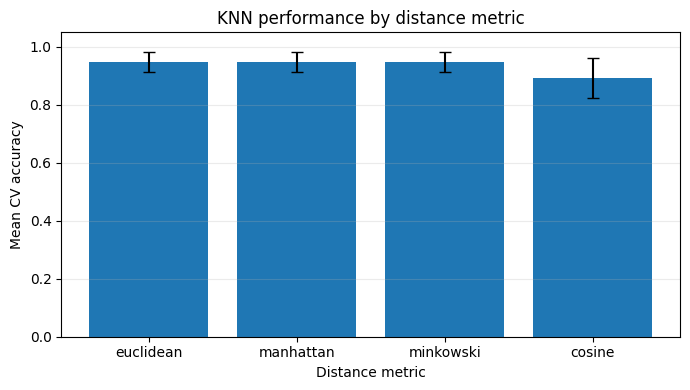

In [3]:
metric_rows = []
for metric in ["euclidean", "manhattan", "minkowski", "cosine"]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5, metric=metric))
    ])
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    metric_rows.append({"metric": metric, "mean_cv_accuracy": scores.mean(),
                        "std_cv_accuracy": scores.std()})
metric_results = pd.DataFrame(metric_rows).sort_values("mean_cv_accuracy", ascending=False)
display(metric_results.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(metric_results["metric"], metric_results["mean_cv_accuracy"],
       yerr=metric_results["std_cv_accuracy"], capsize=4)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Distance metric")
ax.set_ylabel("Mean CV accuracy")
ax.set_title("KNN performance by distance metric")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Hyperparameter tuning with GridSearchCV

Grid search tests combinations of candidate settings using cross-validation. The pipeline keeps scaling inside each fold, helping avoid data leakage.

In [4]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan", "minkowski"]
}
grid = GridSearchCV(knn_pipeline, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print(f"Best mean CV accuracy: {grid.best_score_:.3f}")
best_knn = grid.best_estimator_
best_pred = best_knn.predict(X_test)
print(f"Held-out test accuracy: {accuracy_score(y_test, best_pred):.3f}")
cv_results = pd.DataFrame(grid.cv_results_)
display(cv_results[[
    "param_knn__n_neighbors", "param_knn__weights", "param_knn__metric",
    "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score").head(10).round(3))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 7, 'knn__weights': 'uniform'}
Best mean CV accuracy: 0.955
Held-out test accuracy: 0.947


,param_knn__n_neighbors,param_knn__weights,param_knn__metric,mean_test_score,std_test_score,rank_test_score
7,9,distance,euclidean,0.955,0.041,1
6,9,uniform,euclidean,0.955,0.041,1
5,7,distance,euclidean,0.955,0.041,1
4,7,uniform,euclidean,0.955,0.041,1
12,3,uniform,manhattan,0.955,0.041,1
11,13,distance,euclidean,0.955,0.041,1
9,11,distance,euclidean,0.955,0.041,1
8,11,uniform,euclidean,0.955,0.041,1
13,3,distance,manhattan,0.955,0.041,1
30,9,uniform,minkowski,0.955,0.041,1


## 5. Evaluate classification performance

Accuracy is the fraction of predictions that are correct. A confusion matrix shows which classes are confused. Precision, recall, and F1 provide additional insight, especially when class frequencies or error costs differ.

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.87      1.00      0.93        13
   virginica       1.00      0.85      0.92        13

    accuracy                           0.95        38
   macro avg       0.96      0.95      0.95        38
weighted avg       0.95      0.95      0.95        38



,Predicted setosa,Predicted versicolor,Predicted virginica
Actual setosa,12,0,0
Actual versicolor,0,13,0
Actual virginica,0,2,11


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

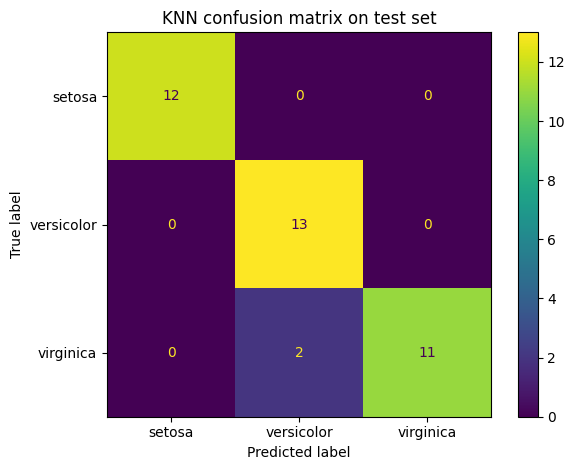

In [5]:
print(classification_report(y_test, best_pred, target_names=iris.target_names, zero_division=0))
cm = confusion_matrix(y_test, best_pred)
display(pd.DataFrame(cm,
    index=[f"Actual {name}" for name in iris.target_names],
    columns=[f"Predicted {name}" for name in iris.target_names]))
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(values_format="d")
plt.title("KNN confusion matrix on test set")
plt.tight_layout()
plt.show()

## 6. Learning curves

Learning curves compare training and cross-validation performance as the amount of training data increases. A large gap can suggest overfitting; low scores on both may suggest underfitting or weak features.

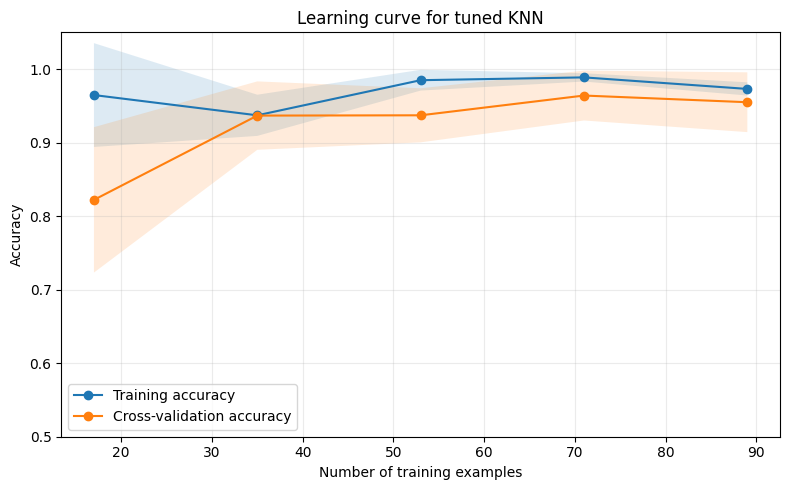

In [6]:
sizes, train_scores, val_scores = learning_curve(
    best_knn, X_train, y_train, train_sizes=np.linspace(0.2, 1.0, 5),
    cv=5, scoring="accuracy", n_jobs=-1
)
train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sizes, train_mean, marker="o", label="Training accuracy")
ax.plot(sizes, val_mean, marker="o", label="Cross-validation accuracy")
ax.fill_between(sizes, train_mean-train_std, train_mean+train_std, alpha=0.15)
ax.fill_between(sizes, val_mean-val_std, val_mean+val_std, alpha=0.15)
ax.set_xlabel("Number of training examples")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.5, 1.05)
ax.set_title("Learning curve for tuned KNN")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. KNN regression

KNN can also be used for regression: it commonly averages target values from nearby training samples. MSE measures squared prediction error; \(R^2\) compares performance with a constant-mean baseline.

Test MSE: 603.54
Test R²: 0.817


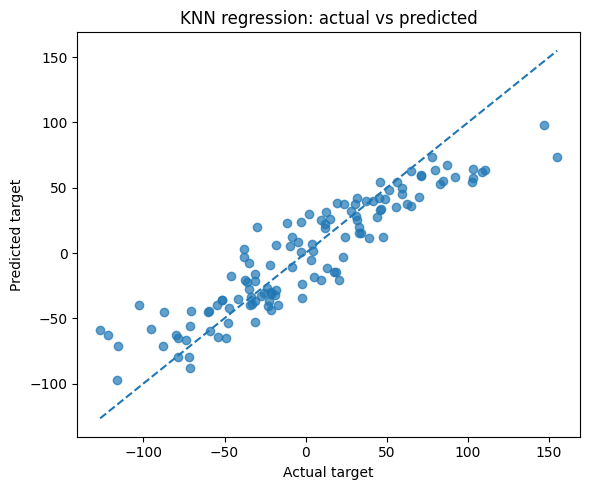

In [7]:
X_reg, y_reg = make_regression(n_samples=500, n_features=4, n_informative=3,
                               noise=18.0, random_state=RANDOM_STATE)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=RANDOM_STATE
)
knn_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=7, weights="distance"))
])
knn_reg.fit(Xr_train, yr_train)
reg_pred = knn_reg.predict(Xr_test)
print(f"Test MSE: {mean_squared_error(yr_test, reg_pred):.2f}")
print(f"Test R²: {r2_score(yr_test, reg_pred):.3f}")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(yr_test, reg_pred, alpha=0.7)
low, high = min(yr_test.min(), reg_pred.min()), max(yr_test.max(), reg_pred.max())
ax.plot([low, high], [low, high], linestyle="--")
ax.set_xlabel("Actual target")
ax.set_ylabel("Predicted target")
ax.set_title("KNN regression: actual vs predicted")
plt.tight_layout()
plt.show()

## 8. Practical exercises

1. Change `n_neighbors` and observe the training/validation scores.
2. Compare uniform and distance-based neighbor weights.
3. Compare distance metrics using cross-validation.
4. Explain why scaling is important for KNN.
5. Use the confusion matrix to identify classes that are confused.
6. Compare regression models with different neighbor counts using MSE and \(R^2\).

## Chapter summary
- KNN predicts from nearby training observations.
- Neighbor count, weighting, and distance metric affect predictions.
- Scaling matters when distance calculations would otherwise be dominated by large-magnitude features.
- Use grid search and cross-validation for hyperparameter tuning.
- Evaluate with confusion matrices and precision/recall/F1 in addition to accuracy.
- Learning curves help examine behavior as the training set grows.
- KNN supports both classification and regression.

## Reference
John Sukup, *scikit-learn Cookbook, Third Edition*, Chapter 4: “Building Models with Distance Metrics and Nearest Neighbors.”